24BAD015 - Bala Harshini B
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)


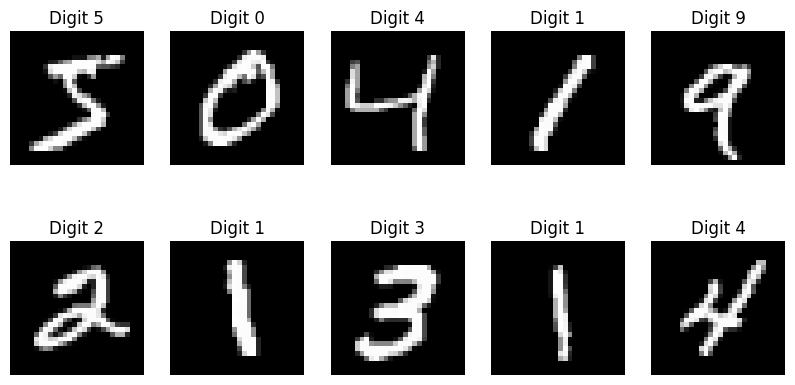

Image dimensions: (28, 28)
Minimum pixel value: 0
Maximum pixel value: 255
Normalized data shape: (60000, 28, 28, 1)
Normalized minimum: -1.0
Normalized maximum: 1.0
Dataset batches prepared successfully!


In [ ]:
print("24BAD015 - Bala Harshini B")
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title("Digit " + str(y_train[i]))
    plt.axis('off')

plt.show()

print("Image dimensions:", x_train[0].shape)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

x_train = (x_train.astype('float32') - 127.5) / 127.5
x_train = np.expand_dims(x_train, axis=-1)

print("Normalized data shape:", x_train.shape)
print("Normalized minimum:", x_train.min())
print("Normalized maximum:", x_train.max())

BUFFER_SIZE = 60000
BATCH_SIZE = 128

train_dataset = tf.data.Dataset.from_tensor_slices(x_train)
train_dataset = train_dataset.shuffle(BUFFER_SIZE).batch(BATCH_SIZE)

print("Dataset batches prepared successfully!")


In [ ]:
print("24BAD015 - Bala Harshini B")
import tensorflow as tf
from tensorflow.keras import layers
NOISE_DIM = 100
generator = tf.keras.Sequential([
    layers.Input(shape=(NOISE_DIM,)),
    layers.Dense(7 * 7 * 128),
    layers.LeakyReLU(negative_slope=0.2),
    layers.Reshape((7, 7, 128)),
    layers.Conv2DTranspose(64, (5, 5), strides=2, padding='same'),
    layers.LeakyReLU(negative_slope=0.2),
    layers.Conv2DTranspose(1, (5, 5), strides=2, padding='same', activation='tanh')
], name="Generator")

discriminator = tf.keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Flatten(),
    layers.Dense(256, name="features"),
    layers.LeakyReLU(negative_slope=0.2),
    layers.Dense(1, activation='sigmoid')
], name="Discriminator")

discriminator.compile(
    optimizer=tf.keras.optimizers.Adam(0.0002),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

discriminator.trainable = False

gan = tf.keras.Sequential([
    generator,
    discriminator
], name="GAN")

gan.compile(
    optimizer=tf.keras.optimizers.Adam(0.0002),
    loss='binary_crossentropy'
)
generator.summary()
discriminator.summary()
gan.summary()


24BAD015 - Bala Harshini B


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6272)           │       633,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │       204,864 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 1)      │         1,601 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 839,937 (3.20 MB)

 Trainable params: 839,937 (3.20 MB)

 Non-trainable params: 0 (0.00 B)

... (6 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Generator (Sequential)          │ (None, 28, 28, 1)      │       839,937 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Discriminator (Sequential)      │ (None, 1)              │       201,217 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,041,154 (3.97 MB)

 Trainable params: 839,937 (3.20 MB)

 Non-trainable params: 201,217 (786.00 KB)

24BAD015 - Bala Harshini B
Epoch: 1 Generator Loss: 1.4735 Discriminator Loss: 0.2161


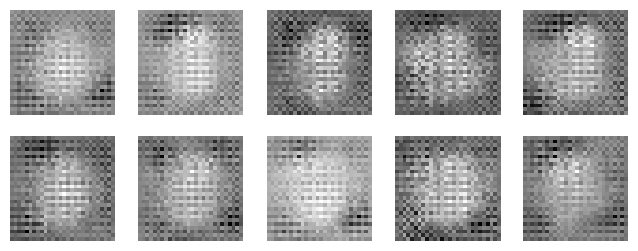

Epoch: 2 Generator Loss: 1.7463 Discriminator Loss: 0.1486


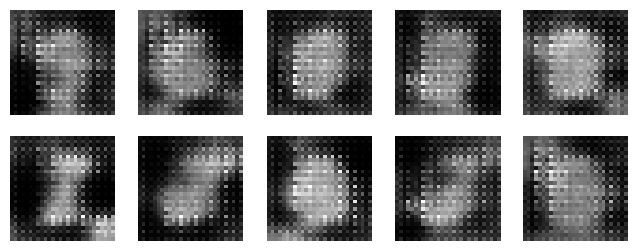

Epoch: 3 Generator Loss: 1.8457 Discriminator Loss: 0.2045


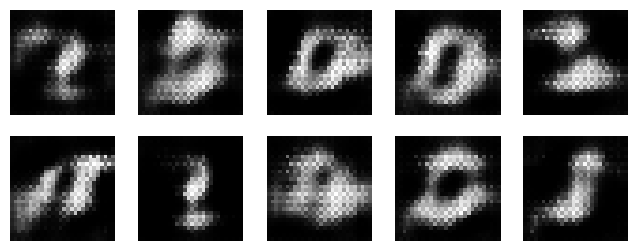

Epoch: 4 Generator Loss: 1.675 Discriminator Loss: 0.2926


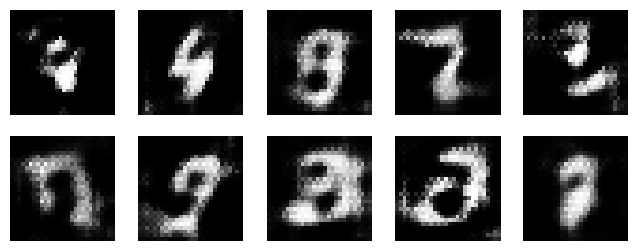

Epoch: 5 Generator Loss: 1.5325 Discriminator Loss: 0.3617


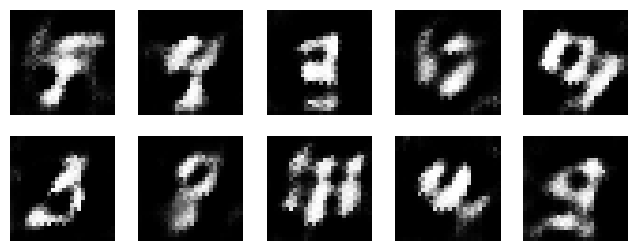

GAN Training Completed!


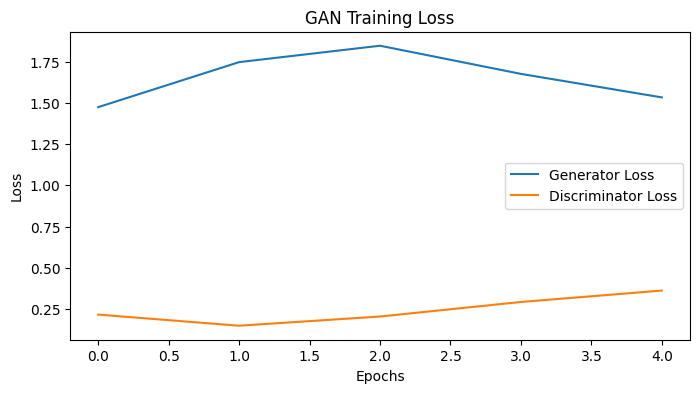

In [ ]:
print("24BAD015 - Bala Harshini B")

import numpy as np
import matplotlib.pyplot as plt

EPOCHS = 5
NOISE_DIM = 100

generator_losses = []
discriminator_losses = []

for epoch in range(EPOCHS):

    g_loss_list = []
    d_loss_list = []

    for real_images in train_dataset:

        current_batch = real_images.shape[0]

        noise = tf.random.normal([current_batch, NOISE_DIM])
        fake_images = generator(noise, training=False)

        real_labels = np.ones((current_batch, 1))
        fake_labels = np.zeros((current_batch, 1))

        discriminator.trainable = True

        d_loss_real = discriminator.train_on_batch(real_images, real_labels)
        d_loss_fake = discriminator.train_on_batch(fake_images, fake_labels)

        d_loss = (d_loss_real[0] + d_loss_fake[0]) / 2

        discriminator.trainable = False

        noise = tf.random.normal([current_batch, NOISE_DIM])
        g_loss = gan.train_on_batch(noise, real_labels)

        g_loss_list.append(float(g_loss))
        d_loss_list.append(float(d_loss))

    generator_losses.append(np.mean(g_loss_list))
    discriminator_losses.append(np.mean(d_loss_list))

    print("Epoch:", epoch + 1,
          "Generator Loss:", round(generator_losses[-1], 4),
          "Discriminator Loss:", round(discriminator_losses[-1], 4))

    noise = tf.random.normal([10, NOISE_DIM])
    generated_images = generator.predict(noise, verbose=0)

    plt.figure(figsize=(8, 3))

    for i in range(10):
        plt.subplot(2, 5, i + 1)
        plt.imshow(generated_images[i, :, :, 0], cmap='gray')
        plt.axis('off')

    plt.show()

print("GAN Training Completed!")

plt.figure(figsize=(8, 4))
plt.plot(generator_losses, label='Generator Loss')
plt.plot(discriminator_losses, label='Discriminator Loss')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("GAN Training Loss")
plt.legend()
plt.show()

24BAD015 - Bala Harshini B


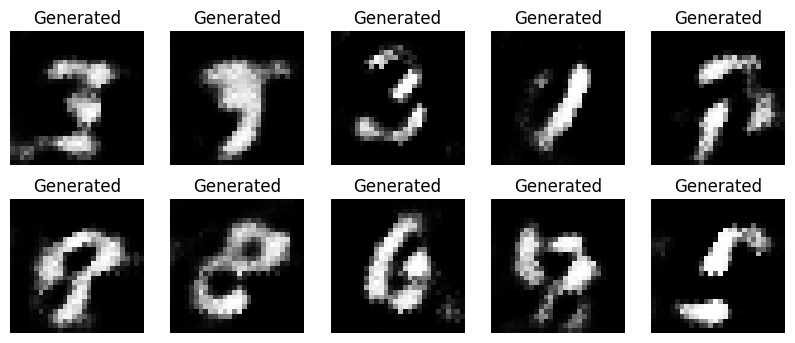

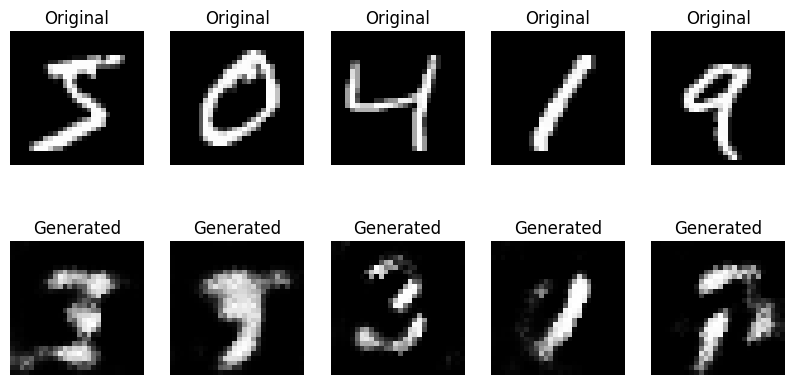

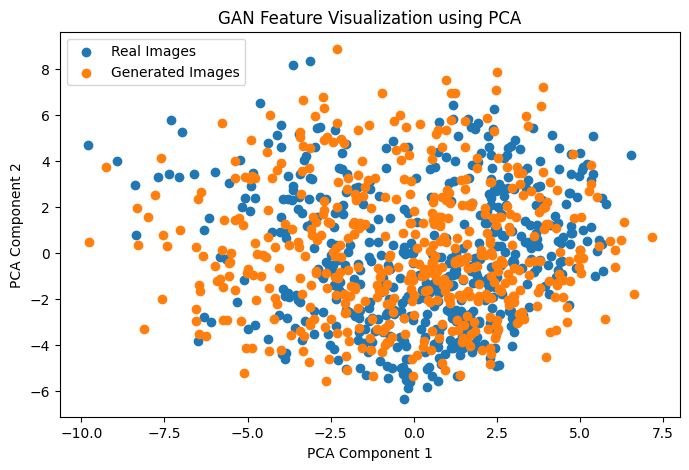

Feature extraction completed!
PCA visualization completed!
GAN Experiment Completed Successfully!


In [ ]:
print("24BAD015 - Bala Harshini B")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.decomposition import PCA
noise = tf.random.normal([10, NOISE_DIM])
generated_images = generator.predict(noise, verbose=0)
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(generated_images[i, :, :, 0], cmap='gray')
    plt.title("Generated")
    plt.axis('off')

plt.show()
plt.figure(figsize=(10, 5))
for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i, :, :, 0], cmap='gray')
    plt.title("Original")
    plt.axis('off')
    plt.subplot(2, 5, i + 6)
    plt.imshow(generated_images[i, :, :, 0], cmap='gray')
    plt.title("Generated")
    plt.axis('off')
plt.show()
feature_model = tf.keras.Sequential(
    list(discriminator.layers[:-1])
)
real_samples = x_train[:500]
noise = tf.random.normal([500, NOISE_DIM])
fake_samples = generator.predict(noise, verbose=0)
real_features = feature_model.predict(real_samples, verbose=0)
fake_features = feature_model.predict(fake_samples, verbose=0)
all_features = np.concatenate(
    [real_features, fake_features], axis=0
)
pca = PCA(n_components=2)
reduced_features = pca.fit_transform(all_features)
plt.figure(figsize=(8, 5))
plt.scatter(
    reduced_features[:500, 0],
    reduced_features[:500, 1],
    label="Real Images"
)
plt.scatter(
    reduced_features[500:, 0],
    reduced_features[500:, 1],
    label="Generated Images"
)
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("GAN Feature Visualization using PCA")
plt.legend()
plt.show()
print("Feature extraction completed!")
print("PCA visualization completed!")
print("GAN Experiment Completed Successfully!")
